In [1]:
import pandas as pd
import matplotlib.pyplot as plt     
import seaborn as sns

data = pd.read_csv('../asset/customer_churn_dataset.csv')
data.head(5)

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


## A. Quick check for data overview and missing values:

Each row is a customer record, but repeated IDs mean that rows do not always represent different customers. The dataset contains three categorical features, seven numeric customer features, a customer ID and the churn label.


### 1. Quick overview:

In [2]:
# Size of the data
data.shape

(505207, 12)

In [3]:
# Struture of the data
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  str    
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  str    
 8   Contract Length    505206 non-null  str    
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), str(3)
memory usage: 46.3 MB


In [4]:
# Descriptive of the data
data.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,505206.0,200779.451782,137241.343095,1.0,63827.25,193039.5,321645.75,449999.0
Age,505206.0,39.704172,12.670577,18.0,29.00,40.0,49.00,65.0
Tenure,505206.0,31.350435,17.237482,1.0,16.00,32.0,46.00,60.0
Usage Frequency,505206.0,15.714825,8.619323,1.0,8.00,16.0,23.00,30.0
Support Calls,505206.0,3.833317,3.133603,0.0,1.00,3.0,6.00,10.0
Payment Delay,505206.0,13.496843,8.451187,0.0,6.00,13.0,20.00,30.0
Total Spend,505206.0,620.072766,245.319256,100.0,446.00,648.9,824.00,1000.0
Last Interaction,505206.0,14.610581,8.608286,1.0,7.00,14.0,22.00,30.0
Churn,505206.0,0.555203,0.496944,0.0,0.00,1.0,1.00,1.0


**Observation:** The dataset contains 505,207 records and 12 columns covering customer details, service usage and churn.


### 2. Checking missing values:

In [5]:
# Check for missing values & missing pct
missing_summary = pd.DataFrame({
    'Missing_Count': data.isna().sum(),
    'Missing_Pct': data.isna().mean() * 100,
})
display(missing_summary.round(4))

,Missing_Count,Missing_Pct
CustomerID,1,0.0002
Age,1,0.0002
Gender,1,0.0002
Tenure,1,0.0002
Usage Frequency,1,0.0002
Support Calls,1,0.0002
Payment Delay,1,0.0002
Subscription Type,1,0.0002
Contract Length,1,0.0002
Total Spend,1,0.0002


In [6]:
# Check for records with missing values
data[data['CustomerID'].isnull()]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Drop records with missing values
data = data[data['CustomerID'].notna()]
data.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [8]:
# Rename columns to lowercase and replace spaces with underscores
data.columns = (data.columns.str.strip().str.lower()
                .str.replace(' ', '_', regex=True)
                .str.replace('customerid', 'customer_id', regex=False))
data.columns

Index(['customer_id', 'age', 'gender', 'tenure', 'usage_frequency',
       'support_calls', 'payment_delay', 'subscription_type',
       'contract_length', 'total_spend', 'last_interaction', 'churn'],
      dtype='str')

**Observation:** One completely empty record was removed, leaving 505,206 records with no missing values.


### 3. The duplicated customer_id issue:

In [9]:
exact_duplicate_count = int(data.duplicated().sum())
print('Dòng trùng toàn bộ 12 cột:', exact_duplicate_count)
data = data.drop_duplicates().copy()

Dòng trùng toàn bộ 12 cột: 0


In [10]:
# Count the number of unique customer IDs and the total count of customer IDs
# To ensure PK is unique and there are no duplicates
print(data['customer_id'].nunique())
print(data['customer_id'].count())

442211
505206


In [11]:
# Check for duplicate customer IDs
test_df = data.groupby('customer_id').size().reset_index(name='row_count')
test_df[test_df['row_count'] > 1]

,customer_id,row_count
1,2.0,2
2,3.0,2
3,4.0,2
4,5.0,2
5,6.0,2
...,...,...
64368,64369.0,2
64369,64370.0,2
64371,64372.0,2
64372,64373.0,2


In [12]:
# Check for a specific customer ID == 64370.0
data[data['customer_id']==64370.0]

,customer_id,age,gender,tenure,usage_frequency,support_calls,payment_delay,subscription_type,contract_length,total_spend,last_interaction,churn
62991,64370.0,36.0,Male,15.0,16.0,6.0,11.0,Standard,Monthly,284.0,22.0,1.0
505202,64370.0,45.0,Female,33.0,12.0,6.0,21.0,Basic,Quarterly,947.0,14.0,1.0


In [13]:
# Get all rows with duplicate customer IDs
duplicate_records = data[
    data.duplicated('customer_id', keep=False)
]

# Count distinct churn labels for each customer ID
churn_counts = duplicate_records.groupby('customer_id')['churn'].nunique()

print('Duplicate customer IDs:', duplicate_records['customer_id'].nunique())
print('Rows with duplicate customer IDs:', len(duplicate_records))
print('Customer IDs with conflicting churn labels:', (churn_counts > 1).sum())

Duplicate customer IDs: 62995
Rows with duplicate customer IDs: 125990
Customer IDs with conflicting churn labels: 32778


In [14]:
# Check how common duplicate customer IDs are in the dataset.
duplicated_id_count = int(test_df['row_count'].gt(1).sum())

print(f'Duplicate customer IDs: {duplicated_id_count / len(test_df):.2%}')
print(f'Rows with duplicate customer IDs: {len(duplicate_records) / len(data):.2%}')

Duplicate customer IDs: 14.25%
Rows with duplicate customer IDs: 24.94%


In [15]:
# Điều chỉnh: phát triển từ cell gốc, giữ cách phân tích từng bước.
list_duplicate_customerid = test_df.loc[test_df['row_count'] > 1, 'customer_id'].unique()
data_final_1 = data[~data['customer_id'].isin(list_duplicate_customerid)].copy()
print('Loại toàn bộ ID lặp:', data_final_1.shape)

data_final_2 = data.drop_duplicates(subset=['customer_id'], keep='first').copy()
print('Trước:', data.shape)
print('Giữ dòng đầu mỗi ID để so sánh:', data_final_2.shape)
assert data_final_1['customer_id'].is_unique


Loại toàn bộ ID lặp: (379216, 12)
Trước: (505206, 12)
Giữ dòng đầu mỗi ID để so sánh: (442211, 12)


**Observation:** There are 62,995 repeated customer IDs, including 32,778 with conflicting churn labels. Removing all records for repeated IDs leaves 379,216 customers for the main analysis.


## B. Quick univariate analyse:

In [16]:
# Check for object columns and their unique values
object_cols = data.select_dtypes(include='object').columns

for col in object_cols:
    print(f'\nColumns: {col}')
    print(data[col].unique())


Columns: gender
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Columns: subscription_type
<StringArray>
['Standard', 'Basic', 'Premium']
Length: 3, dtype: str

Columns: contract_length
<StringArray>
['Annual', 'Monthly', 'Quarterly']
Length: 3, dtype: str


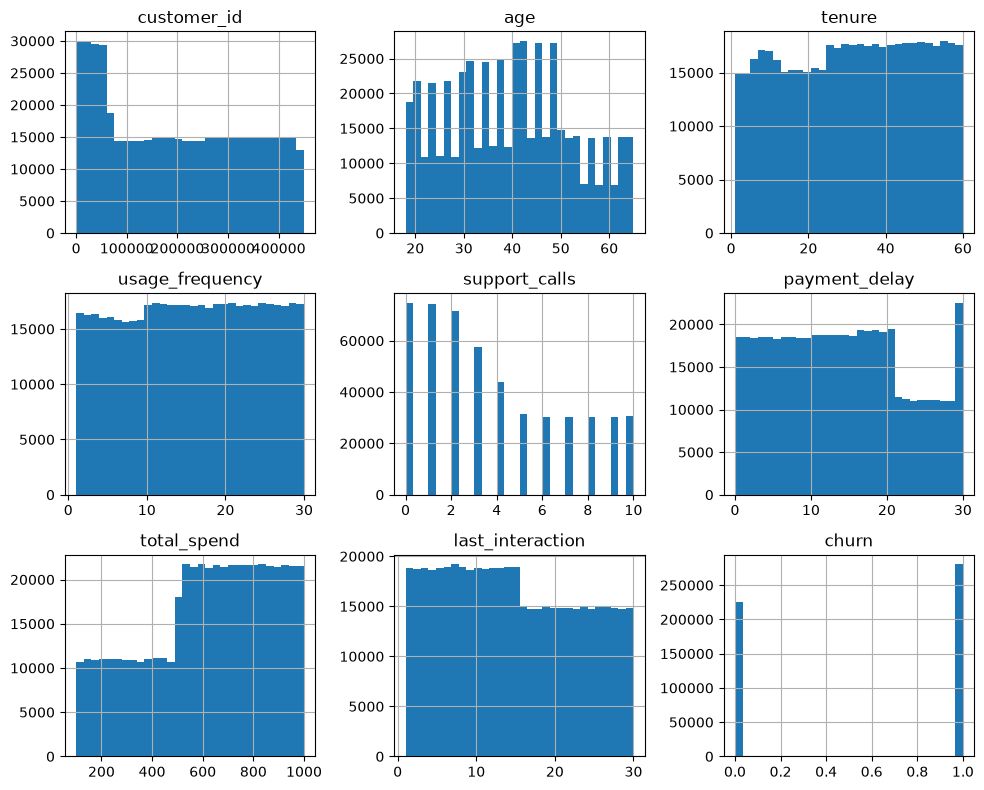

In [17]:
# Check for numeric columns and their unique values
data.select_dtypes(include='number').hist(
    figsize=(10, 8),
    bins=30,
    layout=(-1, 3)
)

plt.tight_layout()
plt.show()

In [18]:
# Identify and summarize outliers in each numeric column using the 1.5 × IQR rule.
summary =[]

numeric_cols = data.select_dtypes(include='number').columns

for cols in numeric_cols:
    Q1 = data_final_1[cols].quantile(0.25)
    Q3 = data_final_1[cols].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    c_outliers = ((data_final_1[cols] < lower_bound) | (data_final_1[cols] > upper_bound)).sum()
    summary.append({'Column': cols, 'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
                    'Lower Bound': lower_bound, 'Upper Bound': upper_bound,
                    'Count of Outliers': int(c_outliers)})
outlier_summary = pd.DataFrame(summary)
display(outlier_summary)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Count of Outliers
0,customer_id,161230.7500,353143.25,191912.5000,-126638.00000,641012.00000,0
1,age,29.0000,48.00,19.0000,0.50000,76.50000,0
2,tenure,16.0000,46.00,30.0000,-29.00000,91.00000,0
3,usage_frequency,9.0000,23.00,14.0000,-12.00000,44.00000,0
4,support_calls,1.0000,5.00,4.0000,-5.00000,11.00000,0
5,payment_delay,6.0000,18.00,12.0000,-12.00000,36.00000,0
6,total_spend,511.0775,836.89,325.8125,22.35875,1325.60875,0
7,last_interaction,7.0000,22.00,15.0000,-15.50000,44.50000,0
8,churn,0.0000,1.00,1.0000,-1.50000,2.50000,0


**Observation:** None of the seven numeric customer features has values outside the 1.5 x IQR limits in the cleaned subset.


## C. Start EDA:

### 1. Churn rate:

#### 1.1 Overall churn rate:

In [19]:
# Calculate the overall churn rate
churn_rate = data_final_1['churn'].value_counts(normalize=True)
print(f'Overall Churn Rate: {churn_rate[1]*100:.2f}%')

Overall Churn Rate: 49.91%


**Observation:** Nearly half of the customers in the cleaned subset have churned, with an overall rate of 49.91%.


#### 1.2 Churn rate by subscription type and contract length

In [20]:
# Calculate churn rate by subscription type and contract length
cat_col = ['subscription_type', 'contract_length']
for col in cat_col:
    summary = (
        data_final_1.groupby(col).agg(
            Total_Ussers = ('churn', 'count'),
            Churned_Users = ('churn', 'sum'),
        )
    )

    summary['Churn_Rate'] = (summary['Churned_Users'] / summary['Total_Ussers'] * 100).round(2)
    print(f"\n===== {col} =====")
    display(summary.round(3))


===== subscription_type =====


,Total_Ussers,Churned_Users,Churn_Rate
subscription_type,,,
Basic,122655,63139.0,51.48
Premium,128087,62873.0,49.09
Standard,128474,63270.0,49.25



===== contract_length =====


,Total_Ussers,Churned_Users,Churn_Rate
contract_length,,,
Annual,156760,61732.0,39.38
Monthly,66240,66099.0,99.79
Quarterly,156216,61451.0,39.34


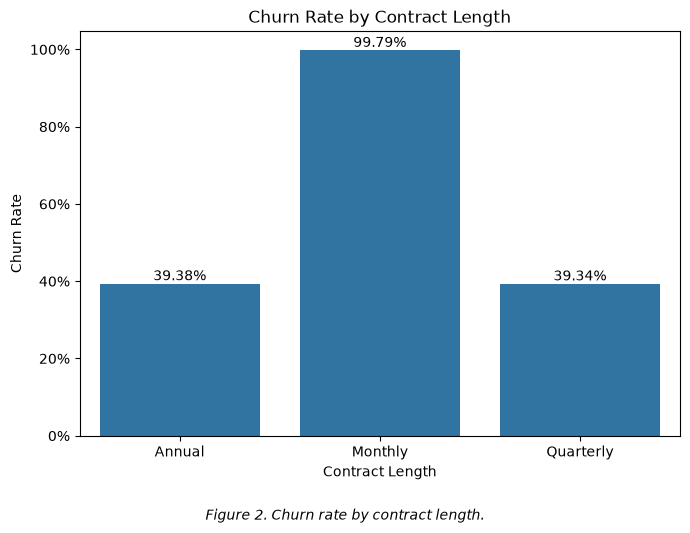

In [21]:
# Calculate churn rate by contract length
churn_rate = (
    data_final_1.groupby('contract_length')['churn']
    .mean()
    .reset_index()
)

# Create a bar plot for churn rate by contract length
plt.figure(figsize=(7, 5))
ax = sns.barplot(x='contract_length', y='churn', data=churn_rate)

plt.title('Churn Rate by Contract Length')
plt.xlabel('Contract Length')
plt.ylabel('Churn Rate')
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.0%}')
)

# Annotate the bars with the churn rate percentage
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2%}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

# Add a caption below the plot
plt.figtext(
    0.5, -0.05,
    "Figure 2. Churn rate by contract length.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.tight_layout()
plt.show()

**Observation:** Monthly contracts have a 99.79% churn rate, compared with about 39% for Annual and Quarterly contracts. Differences between subscription types are much smaller.


#### 1.3 Churn rate by payment delay bucket:

In [22]:
# Calculate descriptive statistics for the 'payment_delay' column
data_final_1['payment_delay'].describe()

count    379216.000000
mean         12.633146
std           8.092188
min           0.000000
25%           6.000000
50%          12.000000
75%          18.000000
max          30.000000
Name: payment_delay, dtype: float64

In [23]:
# Create payment delay buckets and calculate churn rate for each bucket
bins = [0, 5, 10, 15, 20, 25, 30]
labels = [
    '0-5',
    '6-10',
    '11-15',
    '16-20',
    '21-25',
    '26-30'
]

data_final_1['delay_bucket'] = pd.cut(data_final_1['payment_delay'],
                                      bins=bins,
                                      labels=labels,
                                      include_lowest=True
)

summary = (data_final_1.groupby('delay_bucket').agg(
    Total_Users=('churn', 'count'),
    Churned_Users=('churn', 'sum')
))

summary['Churn_Rate'] = (summary['Churned_Users'] / summary['Total_Users'] * 100).round(2)

print("\n===== Payment Delay Bucket =====")
print(summary)


===== Payment Delay Bucket =====
              Total_Users  Churned_Users  Churn_Rate
delay_bucket                                        
0-5                 89599        35548.0       39.67
6-10                74832        29759.0       39.77
11-15               75470        29995.0       39.74
16-20               75255        30012.0       39.88
21-25               32131        32082.0       99.85
26-30               31929        31886.0       99.87


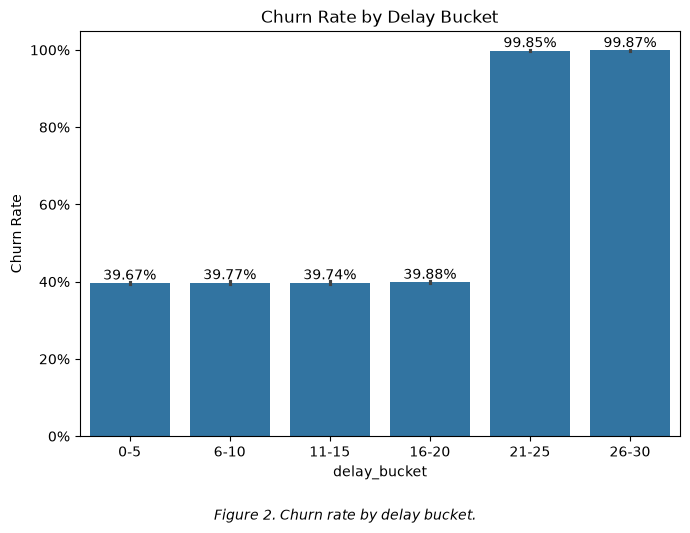

In [24]:

churn_rate = (
    data_final_1.groupby('delay_bucket')['churn']
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=data_final_1, x='delay_bucket', y='churn')

plt.ylabel('Churn Rate')
plt.title('Churn Rate by Delay Bucket')
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.0%}')
)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2%}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.figtext(
    0.5, -0.05,
    "Figure 2. Churn rate by delay bucket.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.tight_layout()
plt.show()


**Observation:** Churn stays around 40% for payment delays of up to 20 days, then rises above 99% in the 21-30 day groups.


### 2. Correlation matrix:

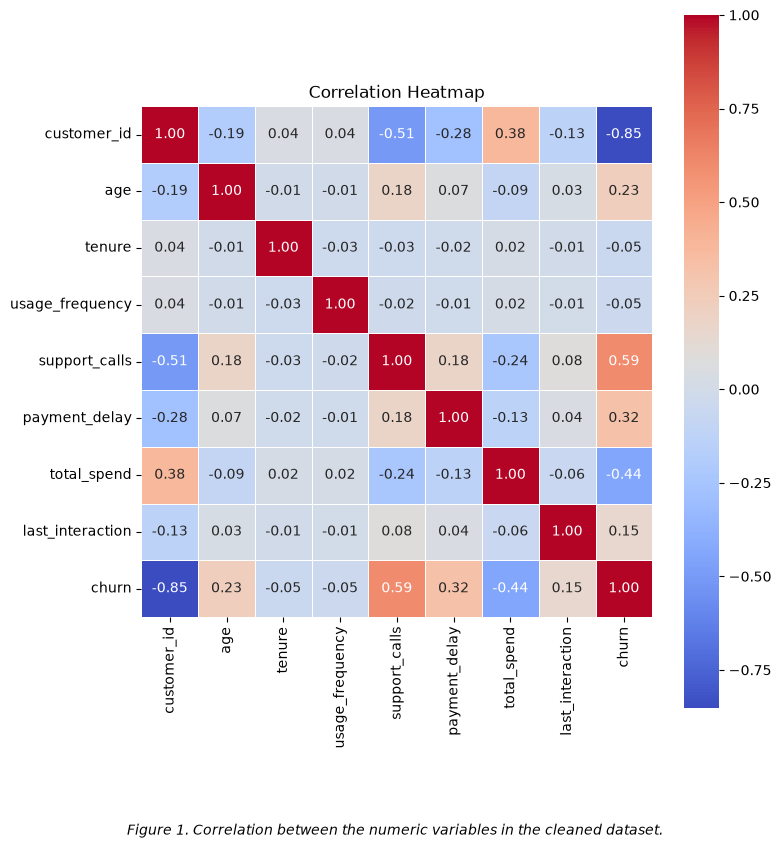

In [25]:

corr_data = data_final_1.select_dtypes(include='number').corr()

plt.figure(figsize=(8, 8))
sns.heatmap(data=corr_data,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5,
            square=True
)

plt.figtext(
    0.5, -0.05,
    "Figure 1. Correlation between the numeric variables in the cleaned dataset.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


**Observation:** Among the numeric customer features, support calls have the strongest positive correlation with churn, while total spend has the strongest negative correlation. Customer ID is an identifier and should not be interpreted as a behavioral feature.


#### 2.1 Relationship between Churn and Support Calls:

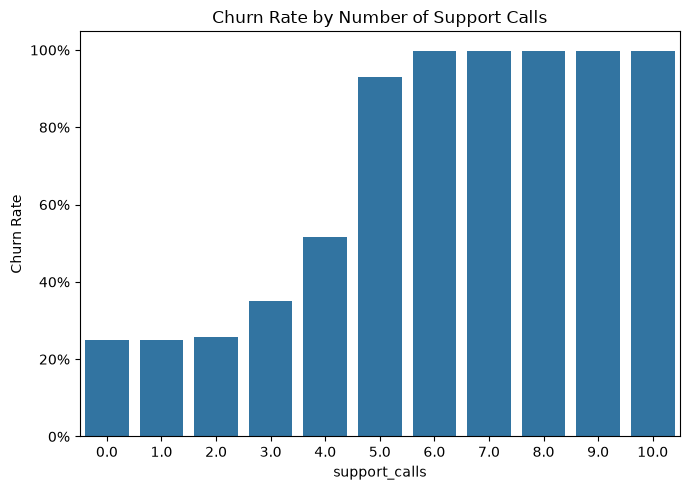

In [26]:
churn_rate = data_final_1.groupby('support_calls')['churn'].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(data=churn_rate, x='support_calls',y='churn')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Number of Support Calls')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()

**Observation:** Churn rises to 93.08% at five support calls and stays around 99.8% at six or more calls.


#### 2.2 Relationship between Churn and Total Spend:

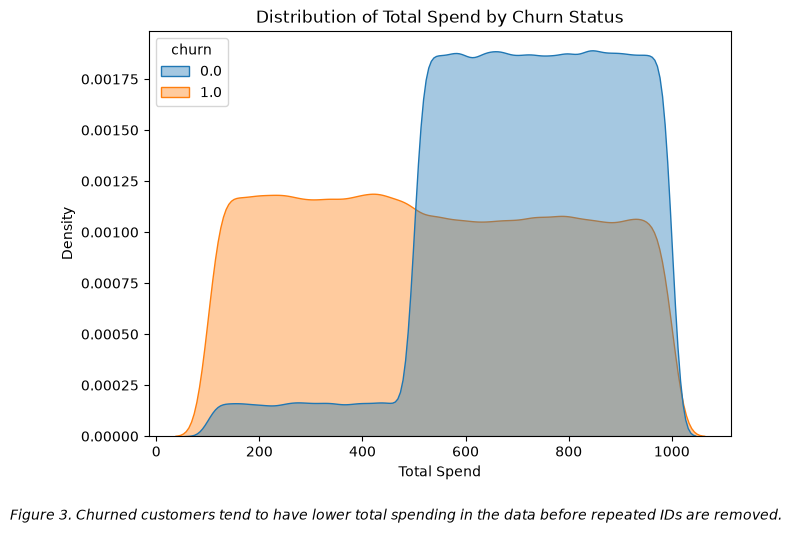

In [27]:
plt.figure(figsize=(7, 5))
sns.kdeplot(data=data, x='total_spend', hue='churn', fill=True, common_norm=False,alpha=0.4)

plt.title('Distribution of Total Spend by Churn Status')
plt.xlabel('Total Spend')
plt.ylabel('Density')

plt.figtext(
    0.5, -0.05,
    "Figure 3. Churned customers tend to have lower total spending in the data before repeated IDs are removed.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.tight_layout()
plt.show()


In [28]:

data_final_1.groupby('churn')['total_spend'].agg(
    ['mean', 'median', 'std']
)

,mean,median,std
churn,,,
0.0,749.515332,749.73,144.858864
1.0,540.643873,532.00,259.951142


**Observation:** The density plot includes repeated IDs. In the cleaned subset, median spend is 532.00 for churned customers and 749.73 for customers who stayed.


### 3. Other findings:

#### 3.1 Relationship between Age and Churn

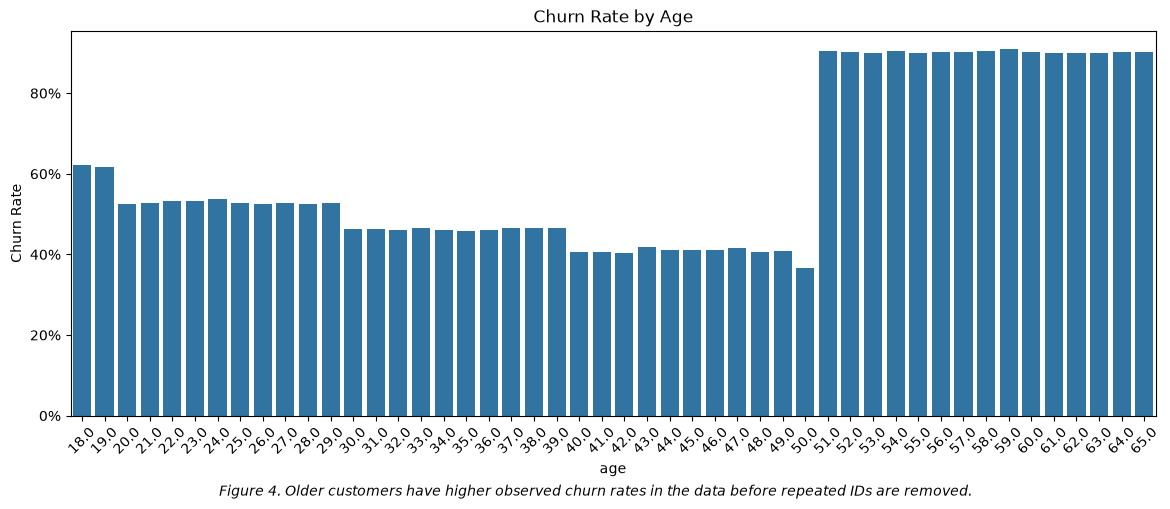

In [29]:
churn_rate = (data.groupby('age')['churn'].mean().reset_index())

plt.figure(figsize=(14,5))
sns.barplot(data=churn_rate,x='age',y='churn')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Age')
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.figtext(
    0.5, -0.05,
    "Figure 4. Older customers have higher observed churn rates in the data before repeated IDs are removed.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.show()


In [30]:
# Percentage of users aged 51+
pct_51_plus = (data_final_1['age'] >= 51).mean() * 100
print(f'Users aged 51+ in data_final_1: {pct_51_plus:.2f}%')
print(f'Churn rate within age 51+: {data_final_1.loc[data_final_1["age"] >= 51, "churn"].mean():.2%}')


Users aged 51+ in data_final_1: 16.35%
Churn rate within age 51+: 99.80%


**Observation:** The age chart includes repeated IDs. In the cleaned subset, customers aged 51+ make up 16.35% of customers and have a 99.80% churn rate.


#### 3.2. Usage Frequency and Churn


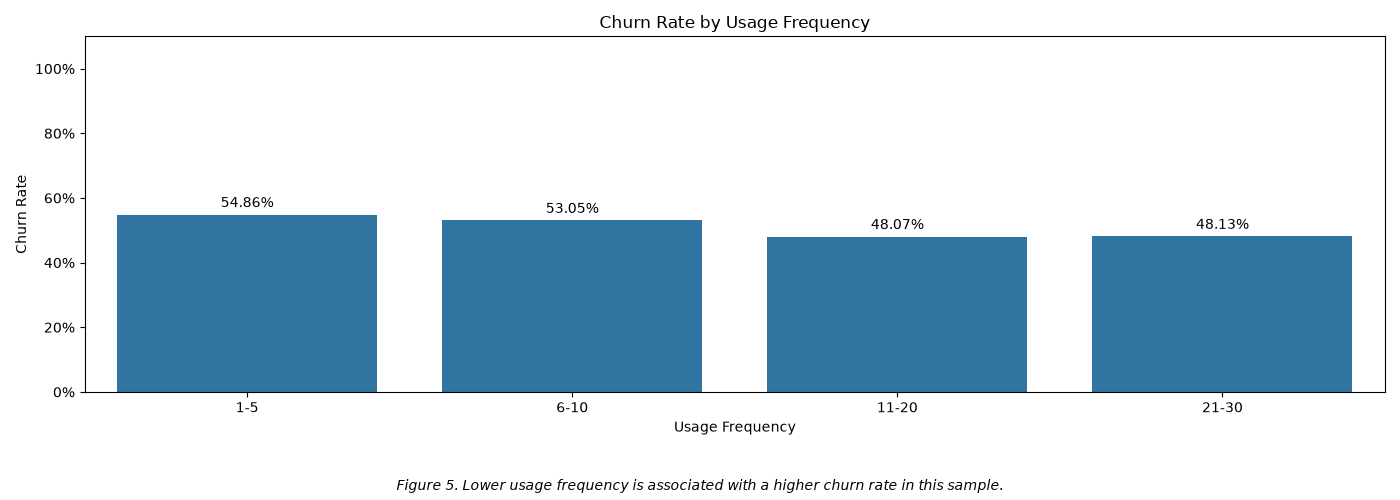

In [31]:
# Compare churn rates across customer groups.
data_final_1['usage_frequency_bucket'] = pd.cut(
    data_final_1['usage_frequency'], bins=[0, 5, 10, 20, 30],
    labels=['1-5', '6-10', '11-20', '21-30'], include_lowest=True
)

churn_rate = data_final_1.groupby('usage_frequency_bucket', observed=True)['churn'].mean().reset_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=churn_rate, x='usage_frequency_bucket', y='churn', errorbar=None)
plt.xlabel('Usage Frequency')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Usage Frequency')
plt.xticks(rotation=0)
plt.ylim(0, 1.10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda value: f'{value:.2%}', padding=3)

plt.figtext(
    0.5, 0.02,
    "Figure 5. Lower usage frequency is associated with a higher churn rate in this sample.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


**Observation:** Churn is 54.86% in the lowest-usage group, compared with about 48% in the two higher-usage groups.


#### 3.3. Last Interaction and Churn


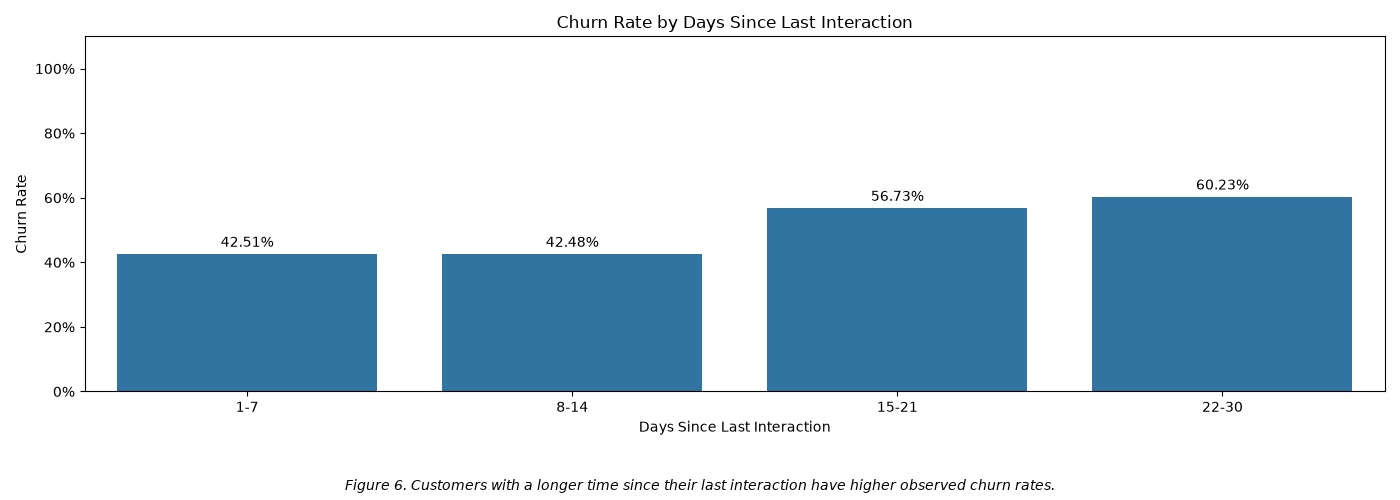

In [32]:
# Compare churn rates across customer groups.
data_final_1['last_interaction_bucket'] = pd.cut(
    data_final_1['last_interaction'], bins=[0, 7, 14, 21, 30],
    labels=['1-7', '8-14', '15-21', '22-30'], include_lowest=True
)

churn_rate = data_final_1.groupby('last_interaction_bucket', observed=True)['churn'].mean().reset_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=churn_rate, x='last_interaction_bucket', y='churn', errorbar=None)
plt.xlabel('Days Since Last Interaction')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Days Since Last Interaction')
plt.xticks(rotation=0)
plt.ylim(0, 1.10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda value: f'{value:.2%}', padding=3)

plt.figtext(
    0.5, 0.02,
    "Figure 6. Customers with a longer time since their last interaction have higher observed churn rates.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


**Observation:** Churn is about 42.5% among customers last active within 14 days, compared with 60.23% for those last active 22-30 days ago.


#### 3.4. Tenure and Churn


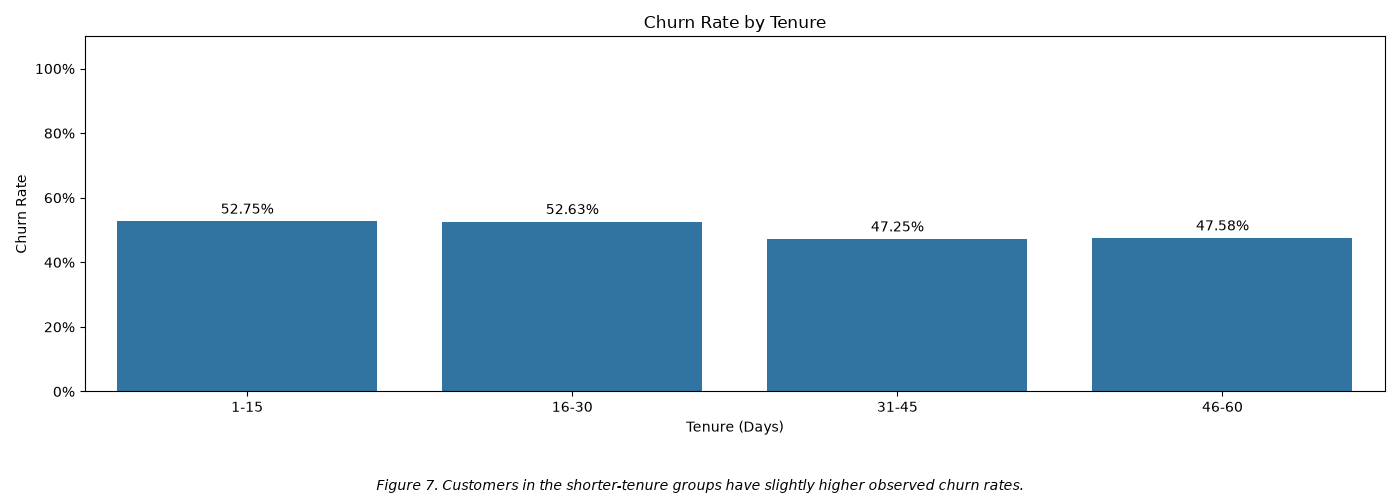

In [33]:
# Compare churn rates across customer groups.
data_final_1['tenure_bucket'] = pd.cut(
    data_final_1['tenure'], bins=[0, 15, 30, 45, 60],
    labels=['1-15', '16-30', '31-45', '46-60'], include_lowest=True
)

churn_rate = data_final_1.groupby('tenure_bucket', observed=True)['churn'].mean().reset_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=churn_rate, x='tenure_bucket', y='churn', errorbar=None)
plt.xlabel('Tenure (Days)')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Tenure')
plt.xticks(rotation=0)
plt.ylim(0, 1.10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda value: f'{value:.2%}', padding=3)

plt.figtext(
    0.5, 0.02,
    "Figure 7. Customers in the shorter-tenure groups have slightly higher observed churn rates.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


**Observation:** Shorter-tenure groups have churn rates around 53%, compared with about 47-48% for longer-tenure groups.


#### 3.5. Gender and Churn


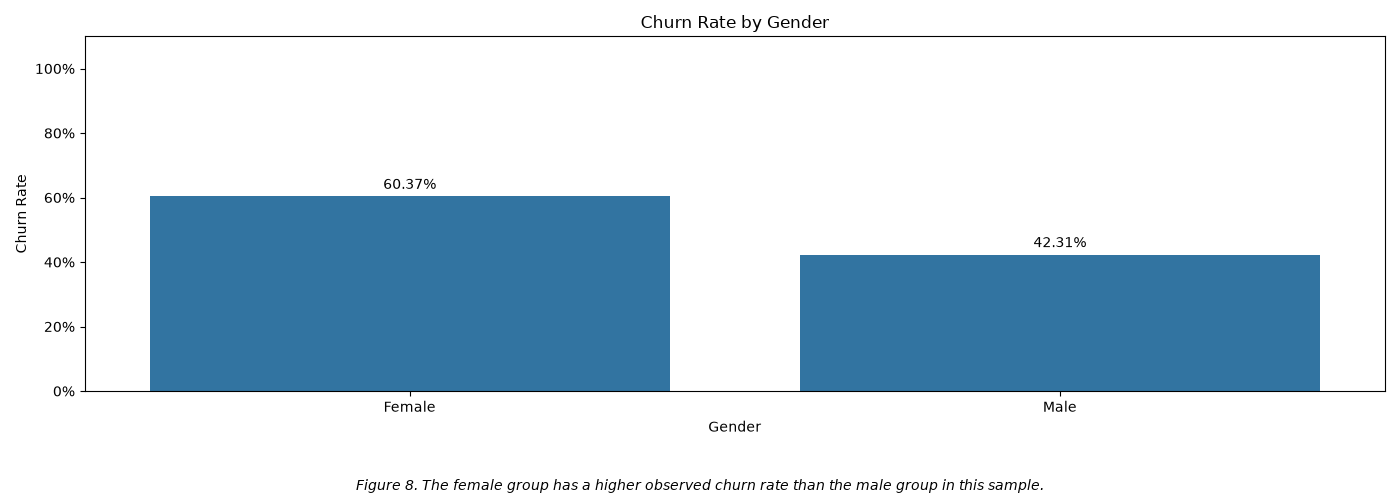

In [34]:
# Compare churn rates across customer groups.
churn_rate = data_final_1.groupby('gender', observed=True)['churn'].mean().reset_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=churn_rate, x='gender', y='churn', errorbar=None)
plt.xlabel('Gender')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Gender')
plt.xticks(rotation=0)
plt.ylim(0, 1.10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda value: f'{value:.2%}', padding=3)

plt.figtext(
    0.5, 0.02,
    "Figure 8. The female group has a higher observed churn rate than the male group in this sample.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


**Observation:** The female group has a higher churn rate than the male group in this sample: 60.37% versus 42.31%.


#### 3.6. Total Spend and Churn


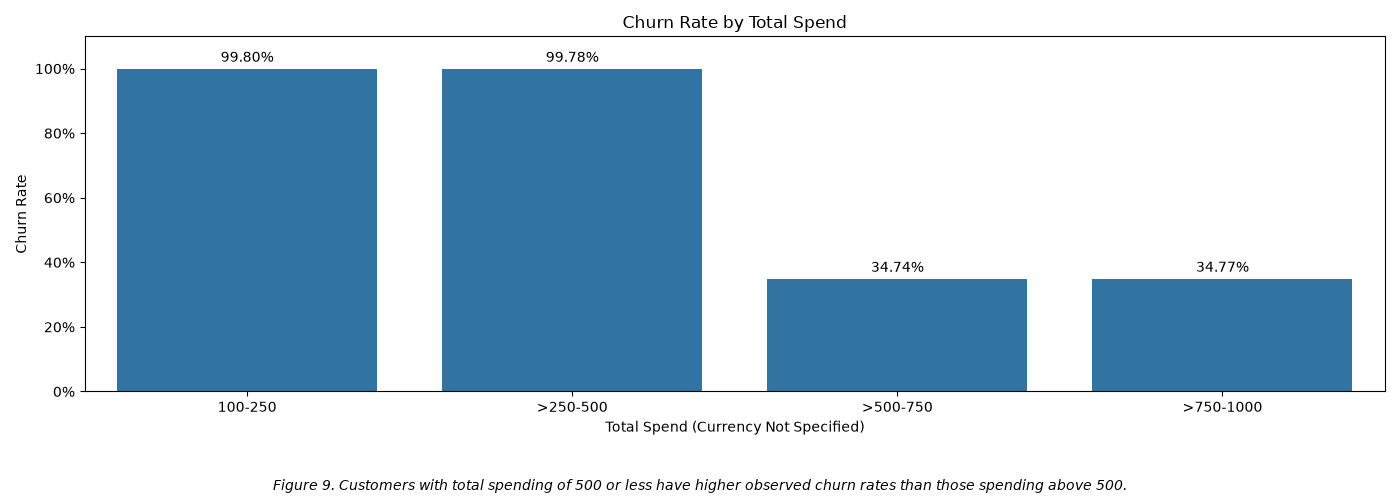

In [35]:
# Compare churn rates across customer groups.
data_final_1['total_spend_bucket'] = pd.cut(
    data_final_1['total_spend'], bins=[0, 250, 500, 750, 1000],
    labels=['100-250', '>250-500', '>500-750', '>750-1000'], include_lowest=True
)

churn_rate = data_final_1.groupby('total_spend_bucket', observed=True)['churn'].mean().reset_index()

plt.figure(figsize=(14, 5))
ax = sns.barplot(data=churn_rate, x='total_spend_bucket', y='churn', errorbar=None)
plt.xlabel('Total Spend (Currency Not Specified)')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Total Spend')
plt.xticks(rotation=0)
plt.ylim(0, 1.10)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda value: f'{value:.2%}', padding=3)

plt.figtext(
    0.5, 0.02,
    "Figure 9. Customers with total spending of 500 or less have higher observed churn rates than those spending above 500.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()


**Observation:** Churn is nearly 100% in the two spending groups up to 500, compared with about 35% in the higher-spending groups.
